# Parcial 2 aplicado – Escenario 1: corredor NQS con lluvia
**Optimización · Universidad Nacional de Colombia · 2026**

Pregunta de planeación: *¿qué servicios (corriente y expresos) operar en la troncal NQS, con qué paradas y frecuencia, para minimizar el costo de operación más el tiempo de los usuarios en la hora pico, y cómo cambia esa decisión con lluvia?*

Este notebook corre de principio a fin. Antes, ejecutar una vez `python preparar_datos.py` (genera `datos/nqs_red.csv` y `datos/nqs_demanda_15min.csv`). El código de los modelos está en `nqs_modelo.py`.

| Bloque | Contenido | Estado |
|---|---|---|
| A | MILP de selección de servicios + Dijkstra/A\* | **este notebook** |
| B | Frecuencias óptimas con hacinamiento (KKT + `scipy.optimize.minimize`) | **este notebook** |
| C | Simulated Annealing vs MILP exacto + frontera de Pareto (ε-restricción) | **este notebook** |
| Sensibilidad | lluvia +20 %, +40 %, estación cerrada, Pareto con lluvia | **este notebook** (sección 10) |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
import nqs_modelo as nm
pd.set_option("display.max_colwidth", 80)
P = nm.PARAMS
pd.Series(P, name="valor").to_frame()

,valor
v_c,25.0
tau_min,0.5
layover_min,5.0
Q,220
c_bus_h,550000
v_tiempo_h,9600
beta,0.1
flota_troncal,2203
frecuencias,"(6, 10, 15, 20, 30, 40)"
kappa,1.0


## 1. Supuestos y parámetros
Detalle y justificación en `supuestos.md`. **Los marcados PROVISIONAL deben confirmarse** antes de la entrega (el PDF califica un dato sin explicación como error).

| Parámetro | Valor | Origen |
|---|---|---|
| Velocidad comercial $v_c$ | 25 km/h | 25,2 km/h en 2024 (rango de fuentes 21–27) |
| Capacidad $Q$ | 220 pax/bus | Promedio ponderado de la flota troncal: 1.320 biarticulados (250) y 610 articulados (160), Informe #99 |
| Parada $\tau$ | 0,5 min | PROVISIONAL (valor típico BRT 20–40 s) |
| Regulación en terminal | 5 min | PROVISIONAL |
| Costo bus-hora $c$ | 550.000 COP | PROVISIONAL. Cadena: costo técnico ≈ 2 × tarifa ($3.550; el Distrito subsidia ~50 %) × IPK troncal ≈ 4,5 pax/km × 25 km/h ≈ 800.000 COP/h; se descuenta ~30 % por combustible (fuera de alcance) |
| Valor del tiempo $v$ | 9.600 COP/h | PROVISIONAL. Salario mínimo 2026 ($1.750.905) / ~182 h al mes (jornada de 42 h) |
| Disuasión $\beta$ | 0,10 1/km | PROVISIONAL (modelo gravitacional) |
| Flota NQS $N^{max}$ | 2.203 × participación de la NQS en las salidas | Informe #99 + salidas nov 2024 |
| Combustible, densidad poblacional | no se modelan | Fuera de alcance según el PDF |

## 2. Datos: red y demanda

In [2]:
red = nm.cargar_red()
participacion = nm.participacion_nqs(red)
FLOTA = round(P["flota_troncal"] * participacion)
am, pm = nm.ventana_pico(red, True), nm.ventana_pico(red, False)
print(f"{red.n} estaciones, eje de {red.km[-1]:.1f} km")
print(f"Participación de la NQS en las salidas troncales: {participacion:.1%}  ->  flota supuesta N = {FLOTA} buses")
print(f"Hora pico mañana: {am[0]}–{am[-1]} (+15 min) | tarde: {pm[0]}–{pm[-1]} (+15 min)")

27 estaciones, eje de 21.6 km
Participación de la NQS en las salidas troncales: 18.8%  ->  flota supuesta N = 414 buses
Hora pico mañana: 07:15–08:00 (+15 min) | tarde: 18:30–19:15 (+15 min)


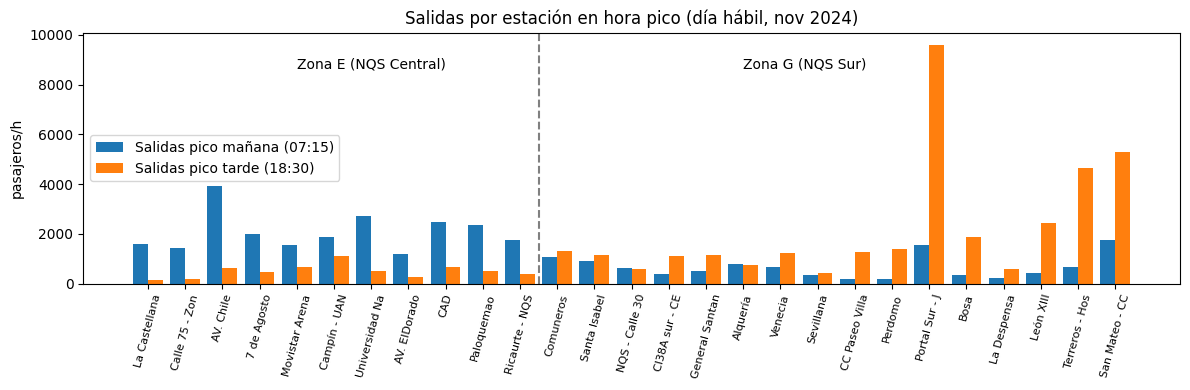

In [3]:
D_am = sum(red.demanda_15[h] for h in am); D_pm = sum(red.demanda_15[h] for h in pm)
x = np.arange(red.n)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(x - 0.2, D_am, 0.4, label=f"Salidas pico mañana ({am[0]})")
ax.bar(x + 0.2, D_pm, 0.4, label=f"Salidas pico tarde ({pm[0]})")
ax.axvline(10.5, color="gray", ls="--"); ax.text(4, max(D_pm) * 0.9, "Zona E (NQS Central)"); ax.text(16, max(D_pm) * 0.9, "Zona G (NQS Sur)")
ax.set_xticks(x, [n[:14] for n in red.nombres], rotation=75, fontsize=8)
ax.set_ylabel("pasajeros/h"); ax.set_title("Salidas por estación en hora pico (día hábil, nov 2024)"); ax.legend()
plt.tight_layout(); plt.show()

**Lectura:** en la mañana las salidas se concentran en la zona E (Av. Chile, U. Nacional, CAD, Paloquemao): la gente **llega** al centro-norte. En la tarde dominan Portal Sur, San Mateo y Terreros: la gente **vuelve** al sur. La demanda tiene dirección, y eso justifica expresos en el sentido del pico.

### Matriz origen-destino (supuesto D3)
No existe una OD pública. Se construye para la hora pico de la mañana:
- Destinos $D_j$ = salidas en el pico de la mañana.
- Orígenes $O_i$ = salidas en el pico de la tarde (quien sale en la tarde por $i$ entró en la mañana por $i$: simetría del viaje de regreso), escaladas a $\sum O = \sum D$.
- Distribución doblemente acotada (Furness): $T_{ij} = A_i O_i B_j D_j e^{-\beta d_{ij}}$.

Viajes en la hora pico: 33,373 pax/h | distancia media 9.2 km
Carga máxima por tramo: hacia el norte 19,010 pax/h, hacia el sur 1,740 pax/h


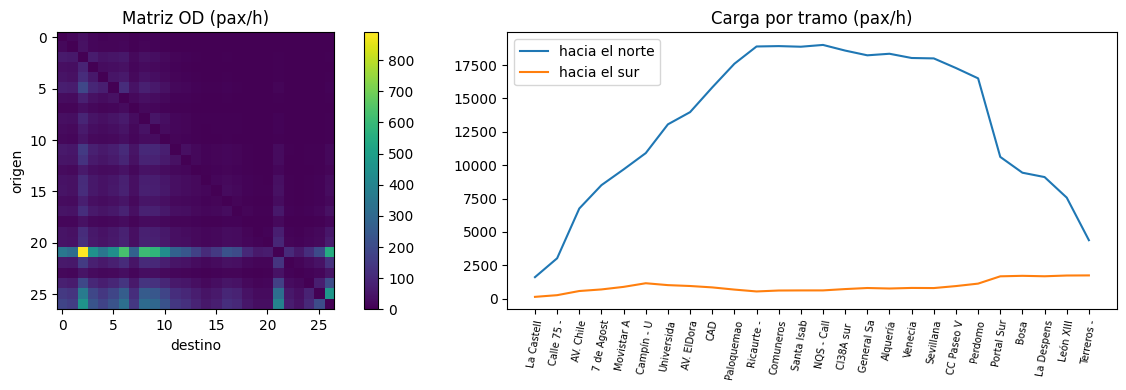

In [4]:
od = nm.construir_od(red)
dist = np.abs(red.km[:, None] - red.km[None, :])
carga_sur = [od[:k+1, k+1:].sum() for k in range(red.n - 1)]
carga_norte = [od[k+1:, :k+1].sum() for k in range(red.n - 1)]
print(f"Viajes en la hora pico: {od.sum():,.0f} pax/h | distancia media {(od*dist).sum()/od.sum():.1f} km")
print(f"Carga máxima por tramo: hacia el norte {max(carga_norte):,.0f} pax/h, hacia el sur {max(carga_sur):,.0f} pax/h")
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
im = axs[0].imshow(od, cmap="viridis"); axs[0].set_title("Matriz OD (pax/h)"); axs[0].set_xlabel("destino"); axs[0].set_ylabel("origen"); plt.colorbar(im, ax=axs[0])
axs[1].plot(carga_norte, label="hacia el norte"); axs[1].plot(carga_sur, label="hacia el sur")
axs[1].set_xticks(range(red.n - 1), [n[:10] for n in red.nombres[:-1]], rotation=80, fontsize=7)
axs[1].set_title("Carga por tramo (pax/h)"); axs[1].legend(); plt.tight_layout(); plt.show()

**Lectura:** el tramo crítico va **hacia el norte**, entre Ricaurte y el centro. Ahí se concentra el "en estas calles colapsa y en otras no". Un servicio corriente con la frecuencia máxima (40 buses/h × 220) mueve 8.800 pax/h. No alcanza para la carga pico, así que hacen falta expresos.

## 3. Bloque A – Selección de servicios, paradas y frecuencias (MILP)

**Conjuntos.** $N$: estaciones (27, de norte a sur). $S$: servicios candidatos. Cada $s$ tiene un patrón de paradas $P_s$ y una frecuencia $f_s \in \{6,10,15,20,30,40\}$ buses/h. Patrones: el corriente (todas las paradas) y expresos entre terminales norte {La Castellana, U. Nacional, Ricaurte} y sur {Portal Sur, San Mateo}, que paran en las $k \in \{2,4,6,8\}$ estaciones intermedias de más movimiento. $K$: pares OD con demanda. $L$: tramos.

**Parámetros.** $D_{od}$ demanda; $\theta_{od,s}$ tiempo en vehículo (recorrido + paradas intermedias); $w_s = 1/(2f_s)$ espera media; $T_s$ ciclo (ida y vuelta + paradas + regulación); $B_s = \lceil f_s T_s \rceil$ buses que requiere; $Q$, $c$, $v$, $N^{max}$.

**Variables.** $y_s \in \{0,1\}$ opera el servicio $s$ (patrón + frecuencia); $x_{od,s} \ge 0$ pasajeros de $o$ a $d$ asignados a $s$.

$$\min \; \sum_s c\,B_s\,y_s \;+\; v \sum_{(o,d)} \sum_s (\theta_{od,s} + w_s)\,x_{od,s}$$
sujeto a
1. Demanda: $\sum_s x_{od,s} = D_{od}$ para todo $(o,d)$.
2. Solo servicios operados que paran en $o$ y $d$: $x_{od,s} \le D_{od}\,y_s$.
3. Capacidad por tramo $\ell$, sentido y servicio: $\sum_{(o,d) \text{ cruzan } \ell} x_{od,s} \le Q f_s y_s$.
4. Flota: $\sum_s B_s y_s \le N^{max}$.
5. El corriente opera con exactamente una frecuencia; cada patrón expreso, con a lo sumo una.

Simplificaciones declaradas: sin transbordos dentro del corredor; la espera se calcula por servicio (no como líneas comunes); los buses se redondean hacia arriba.

In [5]:
servicios = nm.generar_servicios(red, od)
base = nm.resolver_milp(red, od, FLOTA, servicios=servicios)
print(f"Estado: {base.estado} | tiempo de solución: {base.segundos:.1f} s | candidatos: {len(servicios)}")
print(f"Costo total: {base.objetivo/1e6:,.1f} M COP/h  (operación {base.costo_operacion/1e6:,.1f} + usuarios {base.costo_usuarios/1e6:,.1f})")
print(f"Buses usados: {base.buses} de {FLOTA} | horas-usuario: {base.horas_usuario:,.0f}")

def tabla(res):
    return pd.DataFrame([{"servicio": s.patron, "f (bus/h)": s.f, "buses": s.buses,
                          "ciclo (h)": round(s.T_ciclo_h, 2), "paradas": len(s.paradas),
                          "estaciones": "todas" if s.corriente else ", ".join(red.nombres[i][:14] for i in s.paradas)}
                         for s in res.elegidos])
tabla(base)

Estado: Optimal | tiempo de solución: 12.3 s | candidatos: 150
Costo total: 235.6 M COP/h  (operación 92.4 + usuarios 143.2)
Buses usados: 168 de 414 | horas-usuario: 14,918


,servicio,f (bus/h),buses,ciclo (h),paradas,estaciones
0,Corriente,40.0,93,2.32,27,todas
1,E101-000-k6,10.0,17,1.67,8,"La Castellana, AV. Chile, 7 de Agosto, Campín - UAN, Universidad Na, CAD, Pa..."
2,E101-503-k4,6.0,12,1.97,6,"La Castellana, AV. Chile, Universidad Na, Portal Sur - J, Terreros - Hos, Sa..."
3,E107-000-k4,10.0,13,1.24,6,"Universidad Na, CAD, Paloquemao, Ricaurte - NQS, Comuneros, Portal Sur - J"
4,E107-000-k8,6.0,8,1.31,10,"Universidad Na, AV. ElDorado, CAD, Paloquemao, Ricaurte - NQS, Comuneros, Sa..."
5,E107-503-k8,15.0,25,1.65,10,"Universidad Na, CAD, Paloquemao, Ricaurte - NQS, Comuneros, Portal Sur - J, ..."


**Interpretación de la decisión base:** el corriente a frecuencia máxima cubre todas las estaciones. Los expresos se concentran en los pares con más demanda: Portal Sur / San Mateo hacia U. Nacional, CAD, Paloquemao y Av. Chile, y saltan las estaciones de baja demanda (Sevillana, La Despensa, Calle 30 Sur).

### 3.1 Precio sombra de la flota (relajación LP)
Un MIP no tiene duales. Se resuelve la relajación LP ($0 \le y_s \le 1$) y se lee el dual de la restricción de flota para varios tamaños de flota.

In [6]:
filas = []
for N in [166, 167, 170, 200, FLOTA]:
    r = nm.resolver_milp(red, od, N, relajar=True, servicios=servicios)
    filas.append({"flota N": N, "estado": r.estado, "costo LP (M COP/h)": round(r.objetivo/1e6, 3),
                  "precio sombra (COP/h por bus)": None if r.precio_sombra_flota is None else round(r.precio_sombra_flota)})
pd.DataFrame(filas)

,flota N,estado,costo LP (M COP/h),precio sombra (COP/h por bus)
0,166,Optimal,234.631,-65661
1,167,Optimal,234.596,0
2,170,Optimal,234.596,0
3,200,Optimal,234.596,0
4,414,Optimal,234.596,0


**Interpretación:**
- Con la flota supuesta, la restricción **no está activa**: precio sombra 0. Un bus extra no ahorra nada, porque el modelo ya usa menos buses de los disponibles. El límite real es la capacidad del tramo crítico más el costo $c$ de cada bus.
- Cerca del mínimo factible (≈166 buses), el precio sombra salta a unos **−65.000 COP por hora por bus**: un bus más reduce el costo total en esa cantidad.
- Bajo esa flota, la relajación es infactible: la demanda pico no cabe.
- Para el gerente: con flota escasa, cada bus adicional en la NQS vale ~65.000 COP/h. Con la flota actual, sobran buses en el pico.

### 3.2 Costo marginal de un pasajero adicional (dual de la demanda)

In [7]:
rl = nm.resolver_milp(red, od, FLOTA, relajar=True, servicios=servicios)
pares = [(26, 2), (21, 6), (21, 10), (0, 1)]
pd.DataFrame([{"origen": red.nombres[o], "destino": red.nombres[d], "km": round(dist[o, d], 1),
               "costo marginal (COP/pax)": round(rl.duales_demanda[(o, d)])} for o, d in pares])

,origen,destino,km,costo marginal (COP/pax)
0,San Mateo - CC Unisur,AV. Chile,20.0,13823
1,Portal Sur - JFK Coop. Financiera,Universidad Nacional,12.4,8883
2,Portal Sur - JFK Coop. Financiera,Ricaurte - NQS,9.1,7278
3,La Castellana,Calle 75 - Zona M,1.0,614


**Interpretación:** atender un pasajero más de San Mateo a Av. Chile en la hora pico cuesta ~13.800 COP (su tiempo más la operación). Es casi cuatro veces la tarifa de $3.550. Un viaje corto en el norte cuesta ~600 COP. Esto da contexto al subsidio: el viaje largo del sur en pico es el más caro de servir.

### 3.3 Efecto de fijar variables

In [8]:
mejor_expreso = max((s for s in base.elegidos if not s.corriente), key=lambda s: s.buses)
sin_mejor = nm.resolver_milp(red, od, FLOTA, servicios=servicios, fijar={mejor_expreso.nombre: 0})
sin_expresos = nm.resolver_milp(red, od, FLOTA, servicios=servicios,
                                fijar={s.nombre: 0 for s in servicios if not s.corriente})
print(f"Base: {base.objetivo/1e6:,.2f} M COP/h")
print(f"Fijar {mejor_expreso.nombre} = 0: {sin_mejor.estado}, {sin_mejor.objetivo/1e6:,.2f} M COP/h "
      f"(+{(sin_mejor.objetivo-base.objetivo)/1e6:,.2f} M)")
print(f"Fijar todos los expresos = 0: {sin_expresos.estado}")
tabla(sin_mejor)

Base: 235.62 M COP/h
Fijar E107-503-k8@15 = 0: Optimal, 235.66 M COP/h (+0.04 M)
Fijar todos los expresos = 0: Infeasible


,servicio,f (bus/h),buses,ciclo (h),paradas,estaciones
0,Corriente,40.0,93,2.32,27,todas
1,E101-000-k8,10.0,17,1.70,10,"La Castellana, AV. Chile, 7 de Agosto, Movistar Arena, Campín - UAN, Univers..."
2,E101-503-k4,6.0,12,1.97,6,"La Castellana, AV. Chile, Universidad Na, Portal Sur - J, Terreros - Hos, Sa..."
3,E107-000-k8,15.0,20,1.31,10,"Universidad Na, AV. ElDorado, CAD, Paloquemao, Ricaurte - NQS, Comuneros, Sa..."
4,E107-503-k4,10.0,16,1.59,6,"Universidad Na, CAD, Paloquemao, Portal Sur - J, Terreros - Hos, San Mateo - CC"
5,E107-503-k8,6.0,10,1.65,10,"Universidad Na, CAD, Paloquemao, Ricaurte - NQS, Comuneros, Portal Sur - J, ..."


**Interpretación:**
- **Quitar el expreso principal cuesta muy poco**: el modelo lo reemplaza con otros patrones casi equivalentes. Muchas configuraciones son casi óptimas, lo que motiva el Bloque C: la metaheurística explora ese paisaje plano.
- **Quitar todos los expresos vuelve el problema infactible**: el corriente solo no tiene capacidad para la carga del tramo crítico. Los expresos no son un lujo, son necesarios.

## 4. Bloque A – Ruta más corta (Dijkstra y A\*)
**Grafo:** nodos de estación $i$ y nodos de andén $(s, i)$ para cada servicio elegido.
- Abordar: $i \to (s,i)$ con costo $w_s = 1/(2f_s)$.
- Viajar: $(s,i) \to (s,j)$ siguiente parada, con costo $\frac{|km_j - km_i|}{v_c}(1+r) + \tau$.
- Bajar: $(s,i) \to i$, costo 0.

**Heurística de A\*:** $h(n) = |km_n - km_{destino}| / v_c$. **Es admisible**: todo arco de viaje cuesta al menos $\frac{\Delta km}{v_c}$ (la lluvia $r \ge 0$ y las paradas $\tau \ge 0$ solo suman), y abordar o bajar no reduce el costo. Así $h$ nunca sobreestima.

In [9]:
o, d = 21, 6   # Portal Sur -> Universidad Nacional
filas = []
for lluvia in (0.0, 0.2, 0.4):
    G = nm.grafo_servicios(red, base.elegidos, lluvia)
    for metodo, heur in (("Dijkstra", False), ("A*", True)):
        costo, ruta, exp = nm.a_estrella(G, red, o, d, heuristica=heur)
        filas.append({"lluvia": f"+{lluvia:.0%}", "método": metodo, "tiempo (min)": round(costo*60, 1),
                      "nodos expandidos": exp, "ruta": nm.describir_ruta(red, ruta)})
    # verificación independiente con networkx
    H = nx.DiGraph([(u, w, {"c": c}) for u, lst in G.items() for w, c in lst])
    assert abs(nx.shortest_path_length(H, ("est", o), ("est", d), weight="c") - costo) < 1e-9
pd.DataFrame(filas)

,lluvia,método,tiempo (min),nodos expandidos,ruta
0,+0%,Dijkstra,34.3,70,E101-000-k6: Portal Sur - JFK Coop. Financiera -> Universidad Nacional
1,+0%,A*,34.3,38,E101-000-k6: Portal Sur - JFK Coop. Financiera -> Universidad Nacional
2,+20%,Dijkstra,40.3,71,E101-000-k6: Portal Sur - JFK Coop. Financiera -> Universidad Nacional
3,+20%,A*,40.3,52,E101-000-k6: Portal Sur - JFK Coop. Financiera -> Universidad Nacional
4,+40%,Dijkstra,46.3,71,E101-000-k6: Portal Sur - JFK Coop. Financiera -> Universidad Nacional
5,+40%,A*,46.3,56,E101-000-k6: Portal Sur - JFK Coop. Financiera -> Universidad Nacional


**Interpretación:**
- Dijkstra y A\* dan el mismo tiempo; networkx lo verifica de forma independiente. A\* expande entre 20 % y 45 % menos nodos (38 frente a 70 sin lluvia) porque la heurística guía la búsqueda hacia el destino.
- Con lluvia, el viaje Portal Sur → U. Nacional pasa de ~34 a ~40 y ~46 min. Se mide sobre los servicios de la solución base; en la sección 5 el MILP se vuelve a resolver con lluvia.

## 5. Vista previa de sensibilidad (lluvia)
Se vuelve a resolver el MILP con tiempos +20 % y +40 %. El análisis completo, con estación cerrada, va en la sección de sensibilidad.

In [10]:
filas, decisiones = [], {}
for lluvia in (0.0, 0.2, 0.4):
    r = base if lluvia == 0 else nm.resolver_milp(red, od, FLOTA, lluvia=lluvia)
    decisiones[lluvia] = {s.patron for s in r.elegidos}
    filas.append({"lluvia": f"+{lluvia:.0%}", "costo (M COP/h)": round(r.objetivo/1e6, 1),
                  "operación": round(r.costo_operacion/1e6, 1), "usuarios": round(r.costo_usuarios/1e6, 1),
                  "buses": r.buses, "servicios": ", ".join(sorted(f"{s.patron}@{s.f:g}" for s in r.elegidos))})
display(pd.DataFrame(filas))
print("Entran con lluvia:", decisiones[0.2] - decisiones[0.0], "| Salen:", decisiones[0.0] - decisiones[0.2])

,lluvia,costo (M COP/h),operación,usuarios,buses,servicios
0,+0%,235.6,92.4,143.2,168,"Corriente@40, E101-000-k6@10, E101-503-k4@6, E107-000-k4@10, E107-000-k8@6, ..."
1,+20%,273.4,106.2,167.2,193,"Corriente@40, E101-000-k8@10, E101-503-k4@6, E107-000-k8@15, E107-503-k6@10,..."
2,+40%,311.2,120.5,190.7,219,"Corriente@40, E101-000-k8@10, E101-503-k4@6, E107-000-k8@15, E107-503-k6@10,..."


Entran con lluvia: {'E101-000-k8', 'E107-503-k6', 'E111-503-k6'} | Salen: {'E101-000-k6', 'E107-000-k4', 'E107-503-k8'}


**Lectura preliminar:**
- Con lluvia, el número de buses sube porque los ciclos son más largos para mover la misma demanda.
- La mezcla de expresos cambia: aparece un expreso desde **Ricaurte** y se reorganizan las paradas.
- Si la flota disponible fuera menor que la que exige la lluvia, la decisión cambiaría de forma cualitativa: habría que recortar servicios o aceptar demanda no atendida. Eso se analiza en la sección de sensibilidad.

## 6. Bloque B – Frecuencia óptima con espera y hacinamiento (no lineal)
El Bloque A eligió **qué** servicios operar con frecuencias discretas. El Bloque B toma esos servicios y la asignación de pasajeros, y optimiza la **frecuencia continua** de cada uno.

**Primer intento (modelo clásico de Mohring).** Costo del operador más espera:
$$\min_f \sum_s c\,T_s f_s + v\,\frac{D_s}{2 f_s}$$
Su óptimo libre es $f_s = \sqrt{v D_s / (2 c T_s)}$, alrededor de 9 buses/h para el corriente. Eso está muy por debajo de los 40 que exige la capacidad. En la hora pico de la NQS **la capacidad manda**: todas las restricciones de capacidad quedan activas y el modelo no decide nada (se muestra abajo).

**Modelo usado: se agrega el hacinamiento.** Viajar de pie en un bus lleno es más costoso que viajar sentado. El tiempo en vehículo se pondera por $1 + \kappa\,\rho_s^2$, con $\rho_s = \frac{L_s}{Q f_s}$ la ocupación del tramo crítico. A bus lleno ($\rho = 1$) y $\kappa = 1$, el tiempo vale el doble. Ese orden de magnitud aparece en la literatura de valoración del hacinamiento (multiplicadores de 1,5 a 2 de pie); el valor es **PROVISIONAL**.

$$\min_f \; Z(f) = \sum_s \Big[\, c\,T_s f_s \;+\; v\,\frac{D_s}{2 f_s} \;+\; v\,H_s\Big(1 + \kappa \big(\tfrac{L_s}{Q f_s}\big)^2\Big) \Big]$$
$$\text{s.a.}\quad \sum_s T_s f_s \le N \;\;(\lambda \ge 0), \qquad f_s \ge \tfrac{L_s}{Q} \;\;(\mu_s \ge 0)$$

$D_s$: pasajeros/h del servicio. $H_s$: horas-pasajero en vehículo. $L_s$: carga del tramo crítico. Todo sale de la solución del Bloque A. $Z$ es convexa para $f > 0$ (cada término es convexo), así que las condiciones KKT son **necesarias y suficientes**.

**Condiciones KKT.** Lagrangiano: $\mathcal{L} = Z(f) + \lambda\big(\sum_s T_s f_s - N\big) + \sum_s \mu_s\big(\tfrac{L_s}{Q} - f_s\big)$
1. Estacionariedad: $\;(c+\lambda)\,T_s - \dfrac{v D_s}{2 f_s^2} - \dfrac{2 v \kappa H_s L_s^2}{Q^2 f_s^3} - \mu_s = 0$
2. Factibilidad primal: $\sum_s T_s f_s \le N$, $\;f_s \ge L_s/Q$.
3. Factibilidad dual: $\lambda, \mu_s \ge 0$.
4. Complementariedad: $\lambda\,(\sum_s T_s f_s - N) = 0$, $\;\mu_s\,(L_s/Q - f_s) = 0$.

**Solución desde KKT.** Para un $\lambda$ dado, la estacionariedad con $\mu_s = 0$ tiene una raíz única en cada $f_s$, porque el lado izquierdo crece con $f_s$. Si esa raíz queda por debajo de $L_s/Q$, la capacidad se activa: $f_s = L_s/Q$ y $\mu_s$ sale de la ecuación. Luego se busca $\lambda$:
- si la flota alcanza con $\lambda = 0$, la restricción está inactiva;
- si no, $\lambda > 0$ se ajusta por bisección hasta que $\sum T_s f_s = N$.

Con $\kappa = 0$ la raíz es cerrada: $f_s = \sqrt{v D_s / (2 T_s (c+\lambda))}$.

**Interpretación de $\lambda$:** cuánto bajaría el costo total, en COP por hora, con un bus más en la NQS.

In [11]:
T, D, H, L, nombres_b = nm.datos_frecuencias(base)
pd.DataFrame({"servicio": nombres_b, "f en A (bus/h)": [s.f for s in base.elegidos], "ciclo T (h)": T.round(2),
              "D (pax/h)": D.round(0), "H (pax·h)": H.round(0), "carga crítica L": L.round(0),
              "f mínima = L/Q": (L / P["Q"]).round(2)})

,servicio,f en A (bus/h),ciclo T (h),D (pax/h),H (pax·h),carga crítica L,f mínima = L/Q
0,Corriente,40.0,2.32,22383.0,8074.0,8800.0,40.00
1,E101-000-k6,10.0,1.67,2229.0,1434.0,2200.0,10.00
2,E101-503-k4,6.0,1.97,1340.0,1084.0,1320.0,6.00
3,E107-000-k4,10.0,1.24,2200.0,954.0,2200.0,10.00
4,E107-000-k8,6.0,1.31,1430.0,497.0,1286.0,5.85
5,E107-503-k8,15.0,1.65,3790.0,2016.0,3300.0,15.00


In [12]:
mohring = nm.frecuencias_kkt(T, D, H, L, FLOTA, kappa=0.0)
libre = np.sqrt(P["v_tiempo_h"] * D / (2 * P["c_bus_h"] * T))
pd.DataFrame({"servicio": nombres_b, "Mohring libre sqrt(vD/2cT)": libre.round(1),
              "f mínima por capacidad": (L / P["Q"]).round(1), "f KKT (kappa=0)": mohring.f.round(1),
              "mu_s (COP/h por bus/h)": mohring.mu.round(0)})

,servicio,Mohring libre sqrt(vD/2cT),f mínima por capacidad,f KKT (kappa=0),mu_s (COP/h por bus/h)
0,Corriente,9.2,40.0,40.0,1211359.0
1,E101-000-k6,3.4,10.0,10.0,809257.0
2,E101-503-k4,2.4,6.0,6.0,907360.0
3,E107-000-k4,3.9,10.0,10.0,579128.0
4,E107-000-k8,3.1,5.8,5.8,520574.0
5,E107-503-k8,4.5,15.0,15.0,828631.0


**Con $\kappa = 0$, todas las $\mu_s > 0$:** la capacidad fija la frecuencia y el trade-off entre operador y espera no actúa. Por eso el modelo necesita el término de hacinamiento.

In [13]:
def comparar(T, D, H, L, N, etiqueta):
    k = nm.frecuencias_kkt(T, D, H, L, N); s = nm.frecuencias_scipy(T, D, H, L, N)
    fila = {"caso": etiqueta, "flota N": N, "factible": k.factible}
    if k.factible:
        fila.update({"buses usados": round(k.buses, 1), "lambda KKT (COP/h)": round(k.lam),
                     "lambda scipy (dif. finitas)": round(s.lam), "Z KKT (M COP/h)": round(k.objetivo/1e6, 3),
                     "Z scipy": round(s.objetivo/1e6, 3), "max |f_KKT - f_scipy|": float(np.abs(k.f - s.f).max()),
                     "SLSQP success": s.factible, "capacidad activa en": ", ".join(n for n, m in zip(nombres_b, k.mu) if m > 0) or "ninguno"})
    return fila, k

filas, sol_b = [], {}
for N in (FLOTA, 200, 168):
    fila, k = comparar(T, D, H, L, N, "seco"); filas.append(fila); sol_b[N] = k
display(pd.DataFrame(filas))
pd.DataFrame({"servicio": nombres_b, "f A (discreta)": [s.f for s in base.elegidos],
              **{f"f* N={N}": sol_b[N].f.round(1) for N in sol_b},
              f"ocupación ρ N={FLOTA}": (L / (P["Q"] * sol_b[FLOTA].f)).round(2)})

,caso,flota N,factible,buses usados,lambda KKT (COP/h),lambda scipy (dif. finitas),Z KKT (M COP/h),Z scipy,max |f_KKT - f_scipy|,SLSQP success,capacidad activa en
0,seco,414,True,242.1,0,0,337.533,337.533,2.908250e-08,True,ninguno
1,seco,200,True,200.0,417799,417811,345.215,345.215,2.939171e-08,True,ninguno
2,seco,168,True,168.0,1098576,1098630,367.929,367.929,1.439052e-08,False,"E107-000-k4, E107-000-k8, E107-503-k8"


,servicio,f A (discreta),f* N=414,f* N=200,f* N=168,ocupación ρ N=414
0,Corriente,40.0,58.4,48.3,40.4,0.69
1,E101-000-k6,10.0,14.7,12.1,10.1,0.68
2,E101-503-k4,6.0,9.1,7.5,6.2,0.66
3,E107-000-k4,10.0,14.3,11.8,10.0,0.70
4,E107-000-k8,6.0,8.1,6.6,5.8,0.72
5,E107-503-k8,15.0,21.6,17.8,15.0,0.70


**Interpretación:**
- **KKT y `scipy.optimize.minimize` coinciden** en frecuencias, costo y λ. λ de scipy se estima por diferencias finitas sobre $N$, lo que confirma que el multiplicador es la derivada del costo óptimo respecto a la flota. En $N = 168$, SLSQP reporta `success = False` (casi en el borde de factibilidad), pero su solución coincide con la de KKT.
- **Flota holgada (414):** el óptimo usa ~242 buses, unos 75 más que el mínimo de capacidad, y las frecuencias suben ~45 % sobre las del Bloque A. La ocupación del tramo crítico baja a ~0,68. **Vale la pena operar más buses de los estrictamente necesarios para descongestionar los buses**, porque el costo del hacinamiento lo compensa. λ = 0: la flota no limita.
- **Flota de 200:** λ ≈ 418.000 COP/h. Un bus extra reduce el costo total en esa cantidad, además de pagar su propia operación (c = 550.000). Para los usuarios, cada bus vale ~970.000 COP/h.
- **Flota de 168 (la que usó el Bloque A):** λ ≈ 1,1 millones COP/h. Tres expresos quedan en su mínimo de capacidad ($\mu_s > 0$): sus buses van llenos.

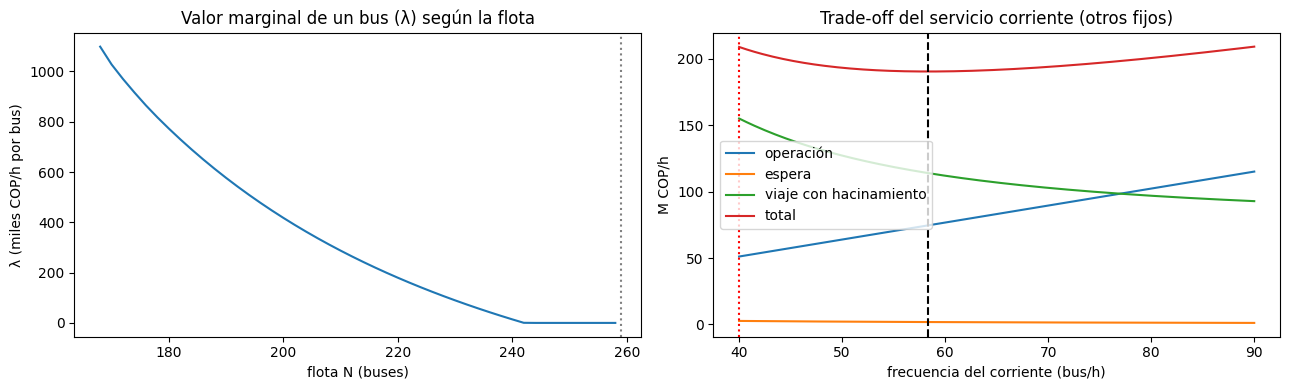

In [14]:
Ns = np.arange(int(np.ceil((L / P["Q"] * T).sum())) + 1, 260, 2)
lams = [nm.frecuencias_kkt(T, D, H, L, N).lam for N in Ns]
fs = np.linspace(L[0] / P["Q"], 90, 200)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(Ns, np.array(lams) / 1e3); axs[0].axvline(FLOTA if FLOTA < 260 else 259, ls=":", color="gray")
axs[0].set_xlabel("flota N (buses)"); axs[0].set_ylabel("λ (miles COP/h por bus)"); axs[0].set_title("Valor marginal de un bus (λ) según la flota")
i = 0
op = P["c_bus_h"] * T[i] * fs; es = P["v_tiempo_h"] * D[i] / (2 * fs)
vi = P["v_tiempo_h"] * H[i] * (1 + P["kappa"] * (L[i] / (P["Q"] * fs)) ** 2)
for y, lab in ((op, "operación"), (es, "espera"), (vi, "viaje con hacinamiento"), (op + es + vi, "total")):
    axs[1].plot(fs, y / 1e6, label=lab)
axs[1].axvline(sol_b[FLOTA].f[i], ls="--", color="k"); axs[1].axvline(L[i] / P["Q"], ls=":", color="r")
axs[1].set_xlabel("frecuencia del corriente (bus/h)"); axs[1].set_ylabel("M COP/h"); axs[1].set_title("Trade-off del servicio corriente (otros fijos)")
axs[1].legend(); plt.tight_layout(); plt.show()

- **Izquierda:** λ es 0 a partir de ~242 buses. Por debajo crece rápido, y cerca del mínimo de capacidad (~166) supera 1 millón COP/h.
- **Derecha:** el costo de operación crece con la frecuencia y el hacinamiento cae. El óptimo (línea negra) queda bastante a la derecha del mínimo de capacidad (línea roja).

In [15]:
filas = []
for lluvia in (0.0, 0.2, 0.4):
    T2, D2, H2, L2, _ = nm.datos_frecuencias(base, red, lluvia)
    for N in (FLOTA, 200):
        fila, k = comparar(T2, D2, H2, L2, N, f"lluvia +{lluvia:.0%}")
        fila["buses mínimos (capacidad)"] = round(float((L2 / P["Q"] * T2).sum()), 1)
        filas.append(fila)
pd.DataFrame(filas)[["caso", "flota N", "factible", "buses mínimos (capacidad)", "buses usados",
                     "lambda KKT (COP/h)", "lambda scipy (dif. finitas)", "Z KKT (M COP/h)", "capacidad activa en"]]

,caso,flota N,factible,buses mínimos (capacidad),buses usados,lambda KKT (COP/h),lambda scipy (dif. finitas),Z KKT (M COP/h),capacidad activa en
0,lluvia +0%,414,True,166.4,242.1,0.0,0.0,337.533,ninguno
1,lluvia +0%,200,True,166.4,200.0,417799.0,417811.0,345.215,ninguno
2,lluvia +20%,414,True,192.2,280.2,0.0,0.0,391.904,ninguno
3,lluvia +20%,200,True,192.2,200.0,950888.0,950909.0,421.530,E107-000-k8
4,lluvia +40%,414,True,218.0,318.3,0.0,0.0,446.273,ninguno
5,lluvia +40%,200,False,218.0,NaN,NaN,NaN,NaN,NaN


**Qué cambia en la decisión con lluvia (no solo en el número):**
- **Con la flota amplia,** la lluvia no cambia las frecuencias (λ sigue en 0). Solo se necesitan más buses en la calle para sostenerlas, porque los ciclos son más largos.
- **Con flota de 200:**
  - En seco, λ ≈ 418.000 COP/h y hay margen para descongestionar los buses.
  - Con +20 %, λ sube a ≈ 951.000 COP/h. Casi todos los buses se van a cumplir la capacidad mínima y el margen contra el hacinamiento desaparece.
  - Con +40 %, el problema es **infactible**: 200 buses no alcanzan ni para la capacidad mínima.
- **Recomendación:** con lluvia fuerte hay que **sumar buses de reserva a la NQS** o recortar servicios (por ejemplo, los expresos de menor demanda) y aceptar parte de la demanda sin atender. Mantener el plan de seco no es posible.

Limitaciones: la asignación de pasajeros a servicios ($D_s$, $H_s$, $L_s$) viene del Bloque A y se mantiene fija; no hay restricción de capacidad del carril ni de las plataformas (buses/h por estación).

## 8. Bloque C – Simulated Annealing contra el método exacto
**Misma instancia que el Bloque A:** para cada uno de los 25 patrones (corriente + 24 expresos) se elige un nivel de frecuencia en {apagado, 6, 10, 15, 20, 30, 40}; el corriente no se puede apagar. Son $6 \times 7^{24} \approx 1{,}1 \times 10^{21}$ diseños posibles.

**Simulated Annealing:**
- **Estado:** el nivel de frecuencia de cada patrón. Se arranca solo con el corriente a 40 buses/h.
- **Vecino:** cambiar el nivel de un patrón al azar (o apagarlo). Con probabilidad 0,3 se apaga además otro expreso (intercambio).
- **Aceptación de Metropolis:** se acepta un vecino peor con probabilidad $e^{-\Delta/T}$. Enfriamiento geométrico desde $T_0 = 0{,}01 \cdot Z_0$ hasta $10^{-5} \cdot Z_0$.
- **Evaluación rápida (~3 ms):** cada par OD se asigna a sus servicios activos del más barato al más caro, hasta agotar la capacidad del tramo. Van primero los pares con menos opciones. La demanda que no cabe se penaliza con 10⁶ COP por pasajero y el exceso de flota con 5·10⁶ COP por bus.
- **Verificación:** al final, el diseño del SA se reevalúa **con el MILP fijando sus $y_s$**, que da la asignación óptima de pasajeros. Así la comparación con el exacto es en la misma función objetivo.

In [16]:
import time
ev = nm.EvaluadorRapido(red, od, servicios, FLOTA)
filas, corridas = [], []
for semilla in range(5):
    sa = nm.recocido_simulado(ev, iteraciones=3000, semilla=semilla)
    exacto_sa = nm.resolver_milp(red, od, FLOTA, servicios=servicios, fijar=ev.a_fijar(sa.estado))
    corridas.append(sa)
    filas.append({"método": f"SA semilla {semilla}", "costo exacto del diseño (M COP/h)": round(exacto_sa.objetivo/1e6, 2),
                  "brecha vs óptimo": f"{(exacto_sa.objetivo/base.objetivo - 1):.2%}", "tiempo (s)": round(sa.segundos, 1),
                  "evaluaciones": sa.evaluaciones, "buses": exacto_sa.buses,
                  "servicios": ", ".join(f"{p}@{sv.f:g}" for p, n in sa.estado.items() if n >= 0
                                         for sv in [servicios[ev.niveles[p][n]]])})
filas.insert(0, {"método": "MILP exacto (HiGHS)", "costo exacto del diseño (M COP/h)": round(base.objetivo/1e6, 2),
                 "brecha vs óptimo": "0.00%", "tiempo (s)": round(base.segundos, 1), "evaluaciones": None,
                 "buses": base.buses, "servicios": ", ".join(f"{s.patron}@{s.f:g}" for s in base.elegidos)})
tabla_sa = pd.DataFrame(filas); tabla_sa

,método,costo exacto del diseño (M COP/h),brecha vs óptimo,tiempo (s),evaluaciones,buses,servicios
0,MILP exacto (HiGHS),235.62,0.00%,12.3,NaN,168,"Corriente@40, E101-000-k6@10, E101-503-k4@6, E107-000-k4@10, E107-000-k8@6, ..."
1,SA semilla 0,243.75,3.45%,10.3,3001.0,188,"Corriente@40, E101-000-k8@20, E101-503-k8@10, E107-503-k8@20, E111-000-k4@6"
2,SA semilla 1,238.81,1.35%,10.4,3001.0,178,"Corriente@40, E101-000-k8@6, E101-503-k6@20, E107-000-k6@6, E107-503-k8@15"
3,SA semilla 2,240.10,1.91%,10.9,3001.0,179,"Corriente@40, E101-000-k6@15, E101-503-k4@10, E107-000-k8@6, E107-503-k8@15,..."
4,SA semilla 3,239.97,1.85%,10.6,3001.0,178,"Corriente@40, E101-000-k8@6, E101-503-k6@15, E107-000-k6@6, E107-503-k6@6, E..."
5,SA semilla 4,241.58,2.53%,10.3,3001.0,179,"Corriente@40, E101-000-k4@10, E101-503-k8@10, E107-000-k4@6, E107-000-k8@10,..."


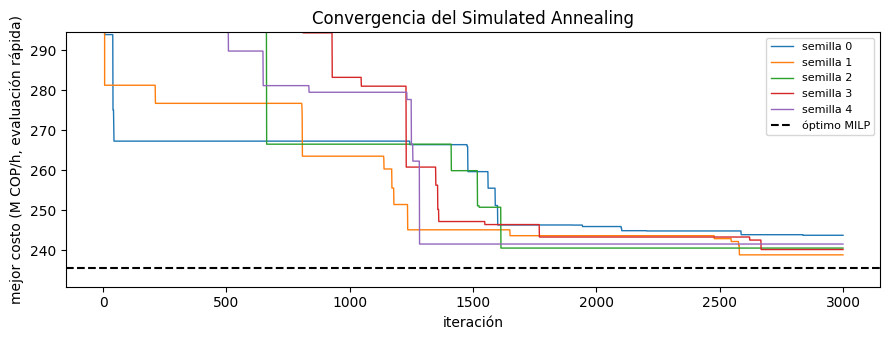

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for k, sa in enumerate(corridas):
    ax.plot(np.array(sa.historia) / 1e6, label=f"semilla {k}", lw=1)
ax.axhline(base.objetivo / 1e6, color="k", ls="--", label="óptimo MILP")
ax.set_ylim(base.objetivo / 1e6 * 0.98, base.objetivo / 1e6 * 1.25)
ax.set_xlabel("iteración"); ax.set_ylabel("mejor costo (M COP/h, evaluación rápida)"); ax.set_title("Convergencia del Simulated Annealing")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretación en la instancia del Bloque A:**
- El SA llega a 1–4 % del óptimo en ~10 s por corrida. Todos sus diseños atienden toda la demanda (verificado con el MILP).
- Aquí el MILP es igual de rápido (~12 s) y **garantiza** el óptimo, así que gana el exacto.
- Los diseños del SA usan patrones distintos con costos parecidos. Es el "paisaje plano" que se vio al fijar variables en el Bloque A.

### Instancia grande: donde la metaheurística sí aporta
Se amplían los candidatos: terminales norte {La Castellana, Av. Chile, U. Nacional, CAD, Ricaurte}, terminales sur {General Santander, Portal Sur, La Despensa, San Mateo}, y $k \in \{2,3,4,5,6,7,8,10\}$ paradas. Son 161 patrones y 966 servicios candidatos.

In [18]:
grande = dict(norte=(0, 2, 6, 8, 10), sur=(15, 21, 24, 26), ks=(2, 3, 4, 5, 6, 7, 8, 10))
serv_g = nm.generar_servicios(red, od, **grande)
milp_g = nm.resolver_milp(red, od, FLOTA, servicios=serv_g, limite_seg=180)
ev_g = nm.EvaluadorRapido(red, od, serv_g, FLOTA)
sa_g = nm.recocido_simulado(ev_g, iteraciones=10000, semilla=0)
ex_g = nm.resolver_milp(red, od, FLOTA, servicios=serv_g, fijar=ev_g.a_fijar(sa_g.estado))
pd.DataFrame([
    {"método": "MILP (límite 180 s)", "estado": milp_g.estado, "costo (M COP/h)": round(milp_g.objetivo/1e6, 2),
     "tiempo (s)": round(milp_g.segundos, 1)},
    {"método": "SA (10.000 iteraciones)", "estado": "heurística", "costo (M COP/h)": round(ex_g.objetivo/1e6, 2),
     "tiempo (s)": round(sa_g.segundos, 1)},
    {"método": "referencia: óptimo de la instancia pequeña", "estado": "Optimal", "costo (M COP/h)": round(base.objetivo/1e6, 2),
     "tiempo (s)": round(base.segundos, 1)},
]).assign(**{"candidatos": [len(serv_g), len(serv_g), len(servicios)]})

,método,estado,costo (M COP/h),tiempo (s),candidatos
0,MILP (límite 180 s),TimeLimit,244.46,183.1,966
1,SA (10.000 iteraciones),heurística,247.76,82.0,966
2,referencia: óptimo de la instancia pequeña,Optimal,235.62,12.3,150


**Interpretación:**
- Con 966 candidatos, el MILP **no termina** en 180 s (estado `TimeLimit`). Entrega la mejor solución encontrada, sin garantía de optimalidad. Construir y resolver el modelo es lo que crece.
- La instancia grande **contiene** a la pequeña (mismos terminales y valores de $k$, más otros), así que su óptimo verdadero cuesta como mucho 235,6 M COP/h. Aun así, el MILP se detuvo a los 180 s en ~244 M: su mejor solución es **peor que un diseño que sabemos factible**. En una prueba aparte con 300 s llegó a 233,0 M, todavía sin probar optimalidad.
- El SA tarda casi lo mismo por iteración que en la instancia pequeña, porque evaluar un diseño no depende del número de candidatos. En ~80 s (menos de la mitad del tiempo) entrega un diseño factible a ~1–2 % de la solución del MILP.
- **Conclusión:** para un número moderado de candidatos se usa el exacto. Si se quiere explorar libremente los patrones de parada ($2^{25}$ por expreso), solo una metaheurística es viable, y el MILP sirve para validar sus soluciones.
- Con más candidatos hay mejores diseños posibles, pero encontrarlos cuesta mucho más. Ninguno de los dos métodos llega al óptimo en minutos. Esto justifica usar el SA para explorar y el MILP para validar.

## 9. Bloque C – Frontera de Pareto: costo de operación vs tiempo de usuarios
Los dos objetivos están en conflicto: más buses reducen la espera y el tiempo de viaje, pero cuestan más. Se usa el **método de ε-restricción** sobre el MILP del Bloque A:
$$\min \;\text{horas-usuario} \quad \text{s.a.}\quad \text{costo de operación} \le \varepsilon,\; \text{restricciones del Bloque A}$$
ε recorre desde el mínimo costo de operación factible hasta el costo del diseño que minimiza el tiempo de los usuarios. A diferencia de la suma ponderada, la ε-restricción encuentra puntos no soportados (en zonas no convexas de la frontera), lo que importa en un problema entero.

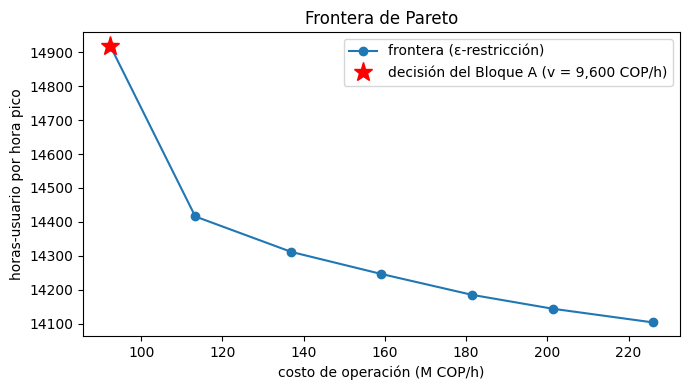

,costo operación (M COP/h),horas_usuario,buses,servicios,valor implícito del tiempo (COP/h)
0,92.4,14918.313819,168,6,NaN
1,113.3,14415.868377,206,4,41597.0
2,137.0,14311.117287,249,5,225773.0
3,159.0,14246.530419,289,6,340627.0
4,181.5,14184.549700,330,6,363823.0
5,201.3,14143.704382,366,6,484756.0
6,226.0,14103.311024,411,6,612724.0


In [19]:
pareto = nm.frontera_pareto(red, od, FLOTA, servicios, puntos=7)
tab_p = pd.DataFrame([{k: v for k, v in p.items() if k != "resultado"} for p in pareto])
tab_p["costo operación (M COP/h)"] = (tab_p["costo_operacion"] / 1e6).round(1)
tab_p["Δ horas / Δ M COP"] = (-tab_p["horas_usuario"].diff() / tab_p["costo operación (M COP/h)"].diff()).round(1)
tab_p["valor implícito del tiempo (COP/h)"] = (tab_p["costo_operacion"].diff() / -tab_p["horas_usuario"].diff()).round(0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tab_p["costo operación (M COP/h)"], tab_p["horas_usuario"], "o-", label="frontera (ε-restricción)")
ax.plot(base.costo_operacion / 1e6, base.horas_usuario, "r*", ms=14, label=f"decisión del Bloque A (v = {P['v_tiempo_h']:,} COP/h)")
ax.set_xlabel("costo de operación (M COP/h)"); ax.set_ylabel("horas-usuario por hora pico"); ax.set_title("Frontera de Pareto")
ax.legend(); plt.tight_layout(); plt.show()
tab_p[["costo operación (M COP/h)", "horas_usuario", "buses", "servicios", "valor implícito del tiempo (COP/h)"]]

**Interpretación para el gerente:**
- La frontera tiene **rendimientos decrecientes**. Los primeros ~21 M COP/h adicionales de operación (unos 38 buses más) ahorran ~500 horas-usuario; los siguientes ahorran cada vez menos (~100 horas o menos por paso).
- La columna *valor implícito del tiempo* indica cuánto debería valer una hora de usuario para que valga la pena moverse al siguiente punto. El primer paso solo se justifica si la hora de usuario vale **~42.000 COP o más**, unas cuatro veces el valor supuesto (9.600 COP/h). Los siguientes pasos exigen más de 200.000 COP/h. Por eso la decisión del Bloque A queda en el extremo de menor costo.
- La frontera mide solo tiempo, sin hacinamiento. El Bloque B mostró que, al contar la incomodidad de los buses llenos, sí conviene operar más buses. Ese efecto movería la recomendación hacia la derecha de la frontera.

## 10. Sensibilidad: lluvia y estación cerrada
Se vuelven a resolver el Bloque A (qué servicios) y el Bloque B (frecuencias con flota limitada a $N = 200$) en seis escenarios.

**Estación cerrada (supuesto E3).** Quien usaba la estación cerrada camina a la anterior o a la siguiente; sus viajes se reparten mitad y mitad entre esas dos vecinas. Los buses pasan sin parar. La caminata se suma al costo de los usuarios: distancia media a las vecinas a 4,5 km/h, por el valor del tiempo. Ese costo no depende de la decisión, pero hace comparables los escenarios.
- **Ricaurte (10):** intercambio con la troncal Américas y terminal norte de algunos expresos. El transbordo con Américas queda fuera del modelo, así que el impacto real sería mayor.
- **Paloquemao (9):** una de las estaciones con más salidas en el pico de la mañana.

In [20]:
V_CAMINATA = 4.5   # km/h (supuesto E3)

def costo_caminata(od_orig, cerradas):
    total = 0.0
    for c in cerradas:
        vecinas = [i for i in (c - 1, c + 1) if 0 <= i < red.n and i not in cerradas]
        km = np.mean([abs(red.km[c] - red.km[v]) for v in vecinas])
        pax = od_orig[c, :].sum() + od_orig[:, c].sum()
        total += pax * km / V_CAMINATA * P["v_tiempo_h"]
    return total

escenarios = [("Seco (base)", 0.0, ()), ("Lluvia +20 %", 0.2, ()), ("Lluvia +40 %", 0.4, ()),
              ("Ricaurte cerrada", 0.0, (10,)), ("Paloquemao cerrada", 0.0, (9,)),
              ("Paloquemao cerrada + lluvia +20 %", 0.2, (9,))]
patrones_base = {f"{s.patron}@{s.f:g}" for s in base.elegidos}
filas, sol_esc = [], {}
for nombre, lluvia, cer in escenarios:
    cer = frozenset(cer)
    od_e = nm.redistribuir_od(od, cer) if cer else od
    rA = base if (lluvia == 0 and not cer) else nm.resolver_milp(red, od_e, FLOTA, lluvia=lluvia, cerradas=cer)
    Tq, Dq, Hq, Lq, _ = nm.datos_frecuencias(rA, red, 0.0)   # T ya incluye la lluvia del escenario
    rB = nm.frecuencias_kkt(Tq, Dq, Hq, Lq, 200)
    elegidos = {f"{s.patron}@{s.f:g}" for s in rA.elegidos}
    camina = costo_caminata(od, cer)
    sol_esc[nombre] = (rA, rB)
    filas.append({"escenario": nombre,
                  "costo A + caminata (M COP/h)": round((rA.objetivo + camina) / 1e6, 1),
                  "buses (A)": rA.buses, "frecuencia corriente": next(s.f for s in rA.elegidos if s.corriente),
                  "entran vs base": ", ".join(sorted(elegidos - patrones_base)) or "—",
                  "salen vs base": ", ".join(sorted(patrones_base - elegidos)) or "—",
                  "B con N=200: λ (COP/h)": round(rB.lam) if rB.factible else "infactible"})
tabla_sens = pd.DataFrame(filas); tabla_sens

,escenario,costo A + caminata (M COP/h),buses (A),frecuencia corriente,entran vs base,salen vs base,B con N=200: λ (COP/h)
0,Seco (base),235.6,168,40.0,—,—,417799
1,Lluvia +20 %,273.4,193,40.0,"E101-000-k8@10, E107-000-k8@15, E107-503-k6@10, E111-503-k6@6","E101-000-k6@10, E107-000-k4@10, E107-000-k8@6, E107-503-k8@15",944179
2,Lluvia +40 %,311.2,219,40.0,"E101-000-k8@10, E107-000-k8@15, E107-503-k6@10, E111-503-k6@6","E101-000-k6@10, E107-000-k4@10, E107-000-k8@6, E107-503-k8@15",infactible
3,Ricaurte cerrada,238.5,168,40.0,"E101-000-k8@10, E107-503-k6@15","E101-000-k6@10, E107-503-k8@15",394902
4,Paloquemao cerrada,238.4,165,30.0,"Corriente@30, E101-000-k8@20, E101-503-k8@10, E111-000-k8@6","Corriente@40, E101-000-k6@10, E101-503-k4@6, E107-000-k4@10",368620
5,Paloquemao cerrada + lluvia +20 %,275.8,189,30.0,"Corriente@30, E101-000-k2@6, E101-000-k8@10, E101-503-k8@10, E107-000-k8@10,...","Corriente@40, E101-000-k6@10, E101-503-k4@6, E107-000-k4@10, E107-000-k8@6",843528


Nota: para que $T_s$ refleje la lluvia en el Bloque B, `datos_frecuencias` recibe los servicios ya construidos con la lluvia del escenario (el MILP los genera así), por eso se llama con `lluvia=0`.

### Frontera de Pareto con lluvia (+20 %)

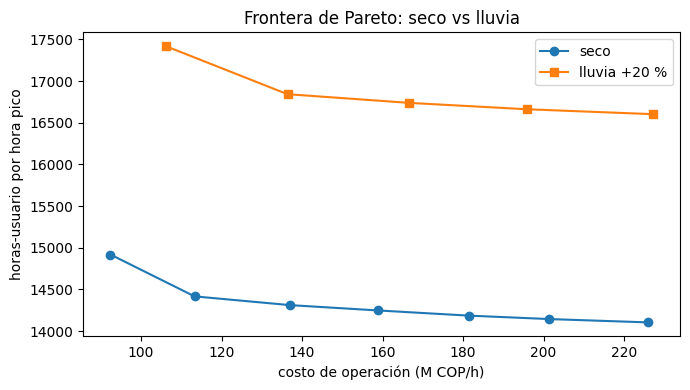

,costo operación (M COP/h),horas_usuario,buses,servicios
0,106.2,17419.416386,193,6
1,136.4,16842.655175,248,4
2,166.6,16738.477018,303,5
3,195.8,16662.025972,356,6
4,227.2,16602.912782,413,6


In [21]:
servicios_ll = nm.generar_servicios(red, od, 0.2)
pareto_ll = nm.frontera_pareto(red, od, FLOTA, servicios_ll, puntos=5, lluvia=0.2)
tab_ll = pd.DataFrame([{k: v for k, v in p.items() if k != "resultado"} for p in pareto_ll])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tab_p["costo_operacion"] / 1e6, tab_p["horas_usuario"], "o-", label="seco")
ax.plot(tab_ll["costo_operacion"] / 1e6, tab_ll["horas_usuario"], "s-", label="lluvia +20 %")
ax.set_xlabel("costo de operación (M COP/h)"); ax.set_ylabel("horas-usuario por hora pico")
ax.set_title("Frontera de Pareto: seco vs lluvia"); ax.legend(); plt.tight_layout(); plt.show()
tab_ll.assign(**{"costo operación (M COP/h)": (tab_ll["costo_operacion"] / 1e6).round(1)})[["costo operación (M COP/h)", "horas_usuario", "buses", "servicios"]]

### Qué cambia en la decisión
Interpretación de la tabla de escenarios y de la frontera (revisar contra las cifras de arriba):
- **Lluvia:** se mantiene el corriente a 40 buses/h, pero cambia la mezcla de expresos y aparece uno desde Ricaurte. La flota necesaria sube de 168 a ~193 (+20 %) y ~219 buses (+40 %). En el Bloque B, con 200 buses, λ se dispara con +20 % y el problema es infactible con +40 %. **La decisión pasa de "cómo repartir los buses" a "de dónde sacar más buses".**
- **Paloquemao cerrada:** la decisión cambia de forma visible. El corriente baja a 30 buses/h y los expresos ganan peso, incluido uno Ricaurte–Portal Sur. La demanda de Paloquemao se concentra en CAD y Ricaurte, que ya son paradas de expreso. El costo para los usuarios sube por la caminata.
- **Ricaurte cerrada:** los cambios son menores. Los expresos reacomodan sus paradas porque Ricaurte deja de serlo, y desaparece la opción del expreso Ricaurte–San Mateo que la lluvia hacía atractiva. Al modelo casi no le cuesta, pero en la realidad el impacto sería mayor: Ricaurte conecta con la troncal Américas y ese transbordo no está modelado. **Es una limitación que se debe declarar.**
- **Pareto con lluvia:** toda la frontera se desplaza hacia arriba y a la derecha. Para el mismo costo de operación hay más horas-usuario, y el punto de mínimo costo exige más buses.

## 11. Pendientes
- Confirmar los parámetros PROVISIONAL de `supuestos.md` (incluidos κ y la velocidad de caminata) y volver a correr.
- Recomendación final para el gerente (media página) y documento de máximo 10 páginas.